# Mini-Projet Data Mining 2026/2027 — Étape 3 & 4 : Modélisation, Optimisation & Évaluation
**Auteurs (Codes Étudiants) :** RSD04 (Team Leader), CS12, CS22, CS29, IASD05, IASD25  
**Parcours :** Classification Supervisée  
**Modèles implémentés (5 familles obligatoires + Baseline) :**
1. **Zero-R (Baseline) :** `DummyClassifier(strategy='most_frequent')`
2. **K-Nearest Neighbors (K-NN) :** Recherche sur $K$, pondérations et métriques de distance (Euclidienne, Manhattan)
3. **Arbre de Décision & Random Forest :** Gini vs Entropie, profondeur maximale, élagage
4. **Naïve Bayes :** `GaussianNB` avec lissage de variance
5. **Support Vector Machines (SVM) :** Noyaux Linéaire, RBF, Poly, hyperparamètres $C$ et $\gamma$ (optimisé sur sous-échantillon stratifié)

---
## 1. Méthodologie d'Optimisation et de Validation Croisée
Conformément aux directives, tous les modèles avec hyperparamètres réglables sont optimisés systématiquement par **GridSearchCV** ou **RandomizedSearchCV** avec une validation croisée stratifiée à 5 plis (**StratifiedKFold, $K=5$, random_state=42**).


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
import joblib

sys.path.append('..')
sys.path.append('.')
from src.models import (
    load_metrics_comparison, load_best_hyperparameters,
    load_feature_importances, load_pipeline
)

print("Chargement des résultats de modélisation...")
df_metrics = load_metrics_comparison()
best_params = load_best_hyperparameters()
feat_imp = load_feature_importances()


Chargement des résultats de modélisation...


## 2. Tableau Comparatif Multicritère des Performances
Toutes les métriques présentées ci-dessous ont été mesurées rigoureusement sur le jeu de test indépendant (25 976 observations) :


In [2]:
display(df_metrics)


,Modèle,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Temps Fit (s),Temps Inférence (s)
0,Zero-R (Baseline),0.565522,0.000000,0.000000,0.000000,0.500000,0.00,0.001
1,K-NN,0.934786,0.944486,0.902977,0.923265,0.980217,0.01,7.935
2,Decision Tree,0.955844,0.958488,0.939040,0.948664,0.987785,85.84,0.007
3,Random Forest,0.962889,0.972619,0.941077,0.956588,0.994227,139.57,0.116
4,Naive Bayes,0.867416,0.863459,0.825359,0.843979,0.925329,2.38,0.018
5,Support Vector Machine,0.952110,0.957870,0.930711,0.944095,0.987720,50.11,11.062


## 3. Hyperparamètres Optimaux Identifiés par Validation Croisée


In [3]:
for model_name, params in best_params.items():
    print(f"=== {model_name} ===")
    for k, v in params.items():
        print(f"  • {k}: {v}")
    print()


=== Zero-R (Baseline) ===
  • strategy: most_frequent

=== K-NN ===
  • metric: manhattan
  • n_neighbors: 11
  • weights: distance

=== Decision Tree ===
  • criterion: entropy
  • max_depth: 20
  • min_samples_leaf: 5
  • min_samples_split: 50

=== Random Forest ===
  • n_estimators: 100
  • min_samples_leaf: 2
  • max_depth: 25
  • criterion: gini

=== Naive Bayes ===
  • var_smoothing: 1e-11

=== Support Vector Machine ===
  • kernel: rbf
  • gamma: scale
  • C: 5.0



## 4. Visualisation des Performances
### 4.1 Courbes ROC Comparées (Capacité Discriminante)


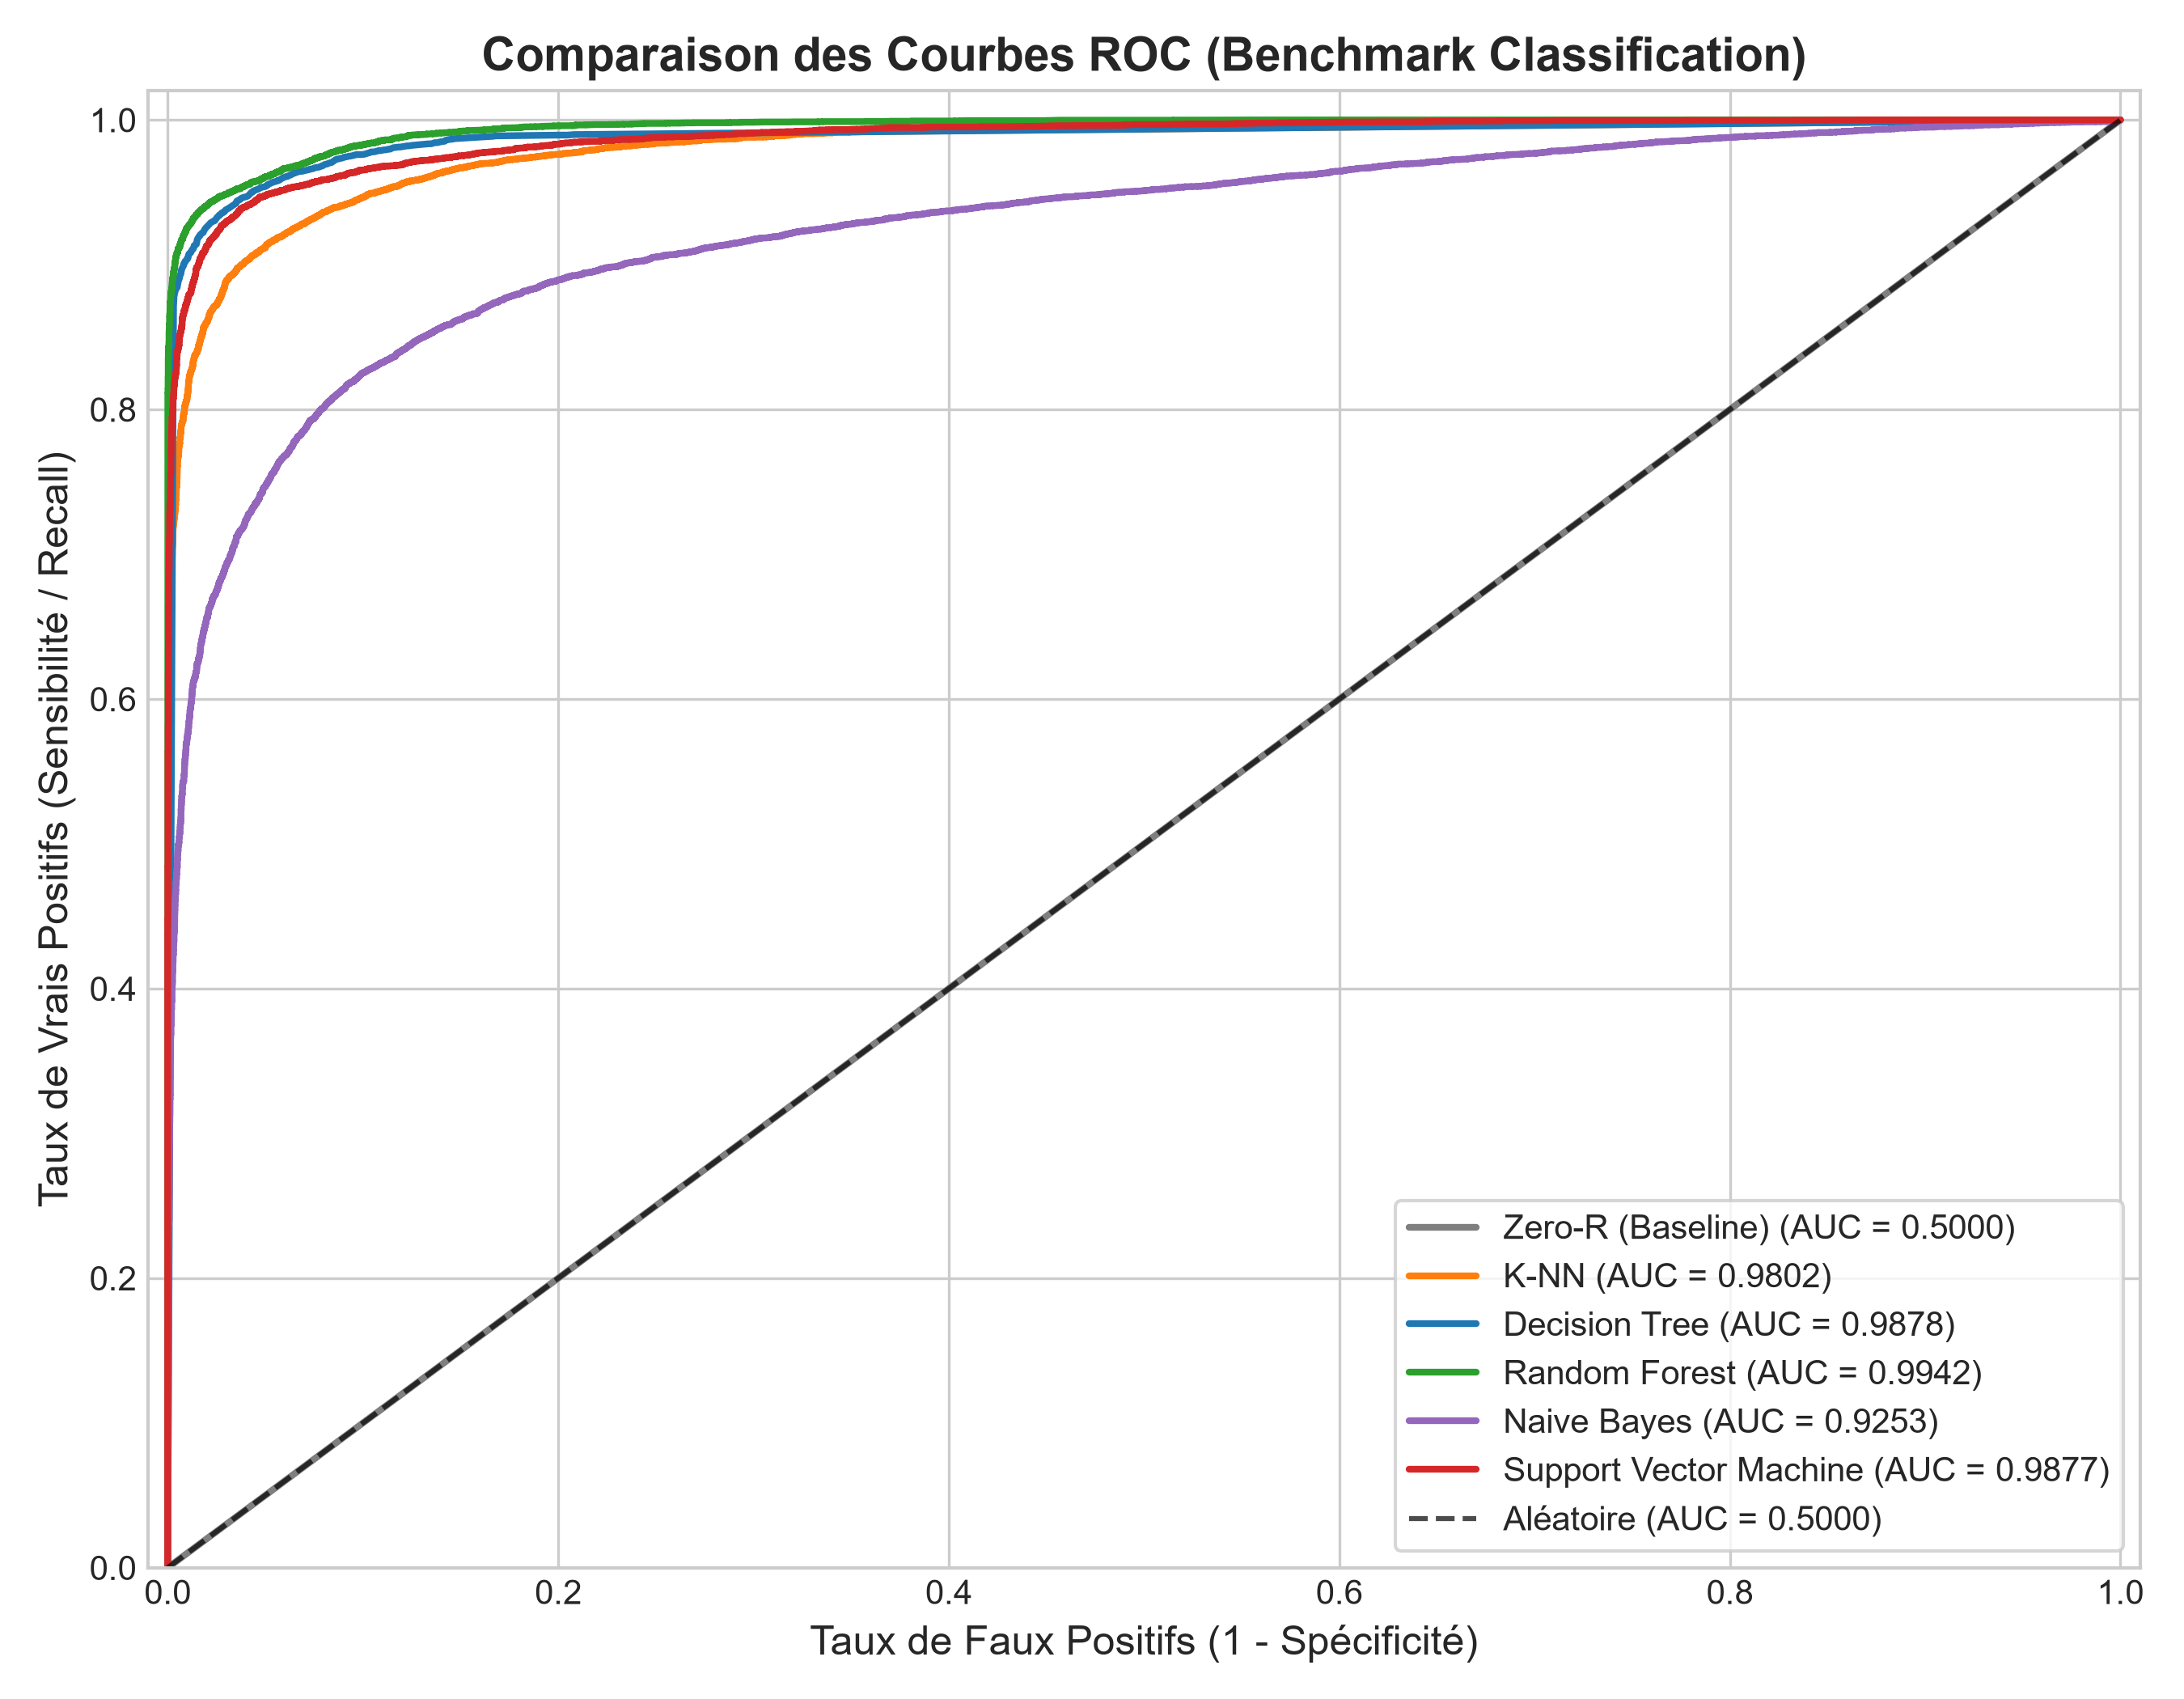

In [4]:
from IPython.display import Image, display

roc_img = "../data/figures/roc_curves_comparison.png"
if not os.path.exists(roc_img):
    roc_img = "data/figures/roc_curves_comparison.png"
if os.path.exists(roc_img):
    display(Image(filename=roc_img))
else:
    print("Image non trouvée, exécutez run_complete_pipeline.py.")


### 4.2 Grille des Matrices de Confusion


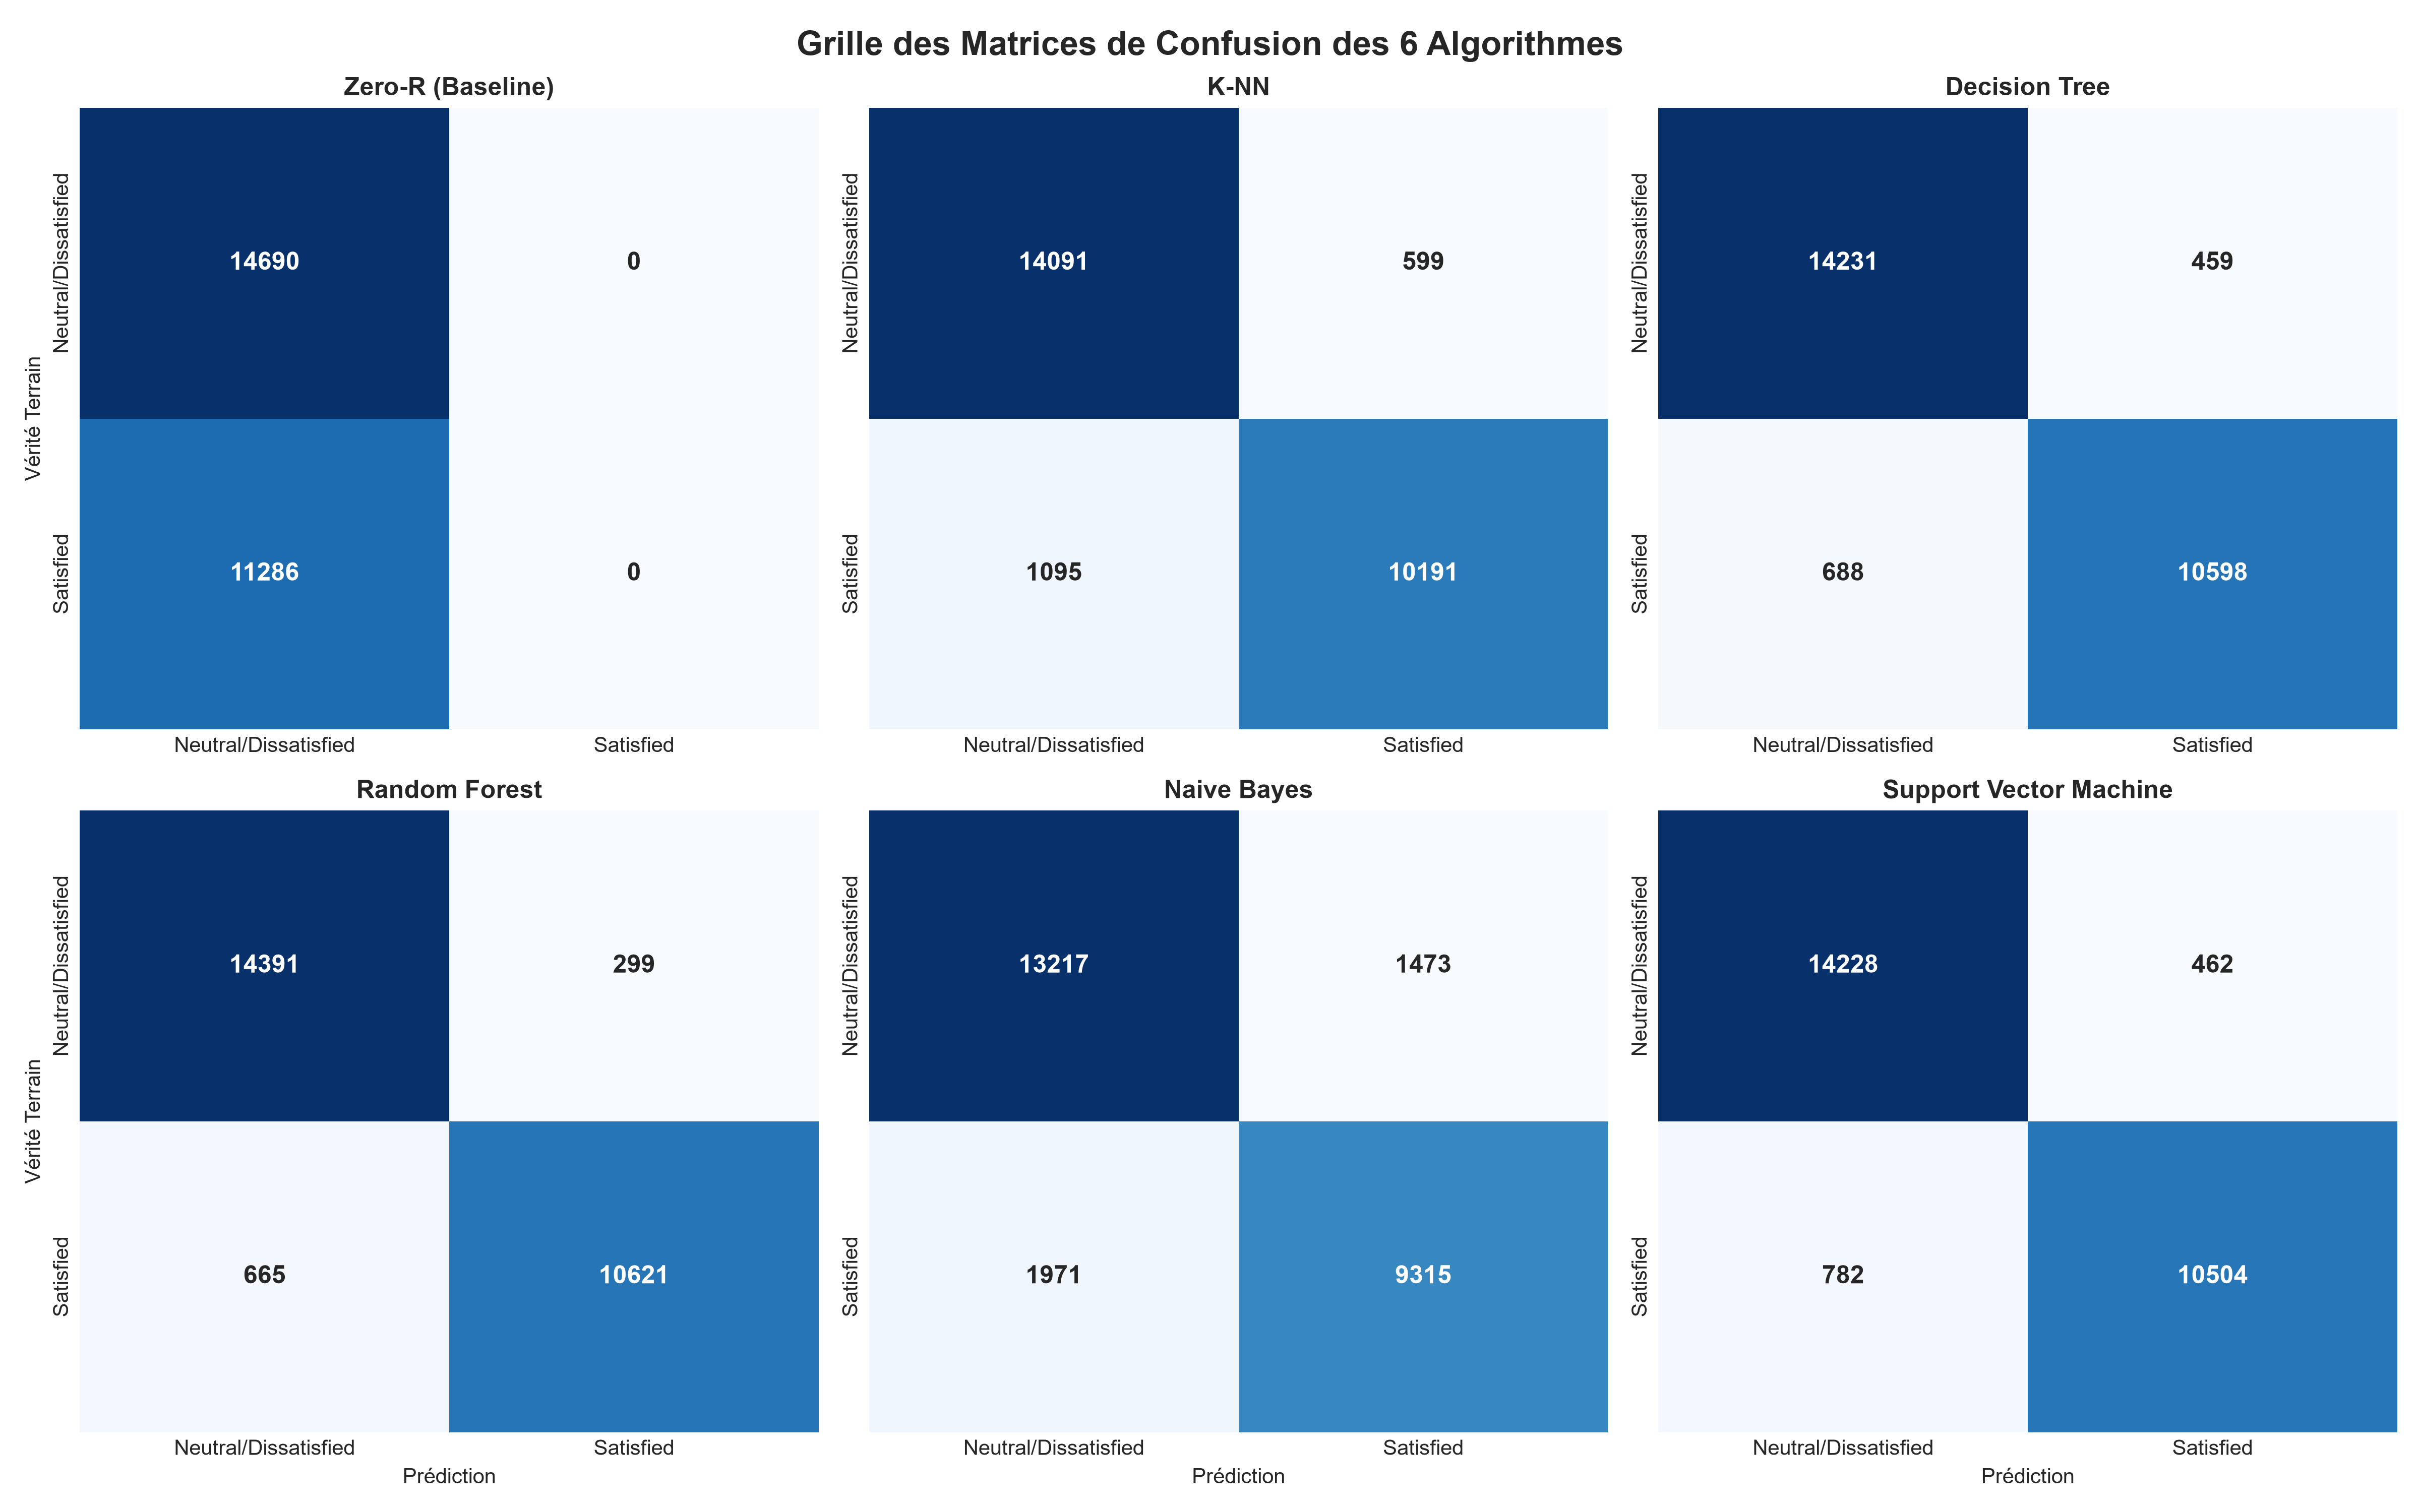

In [5]:
cm_img = "../data/figures/confusion_matrices_grid.png"
if not os.path.exists(cm_img):
    cm_img = "data/figures/confusion_matrices_grid.png"
if os.path.exists(cm_img):
    display(Image(filename=cm_img))


### 4.3 Importance des Variables (Gini, Permutation, Information Mutuelle)


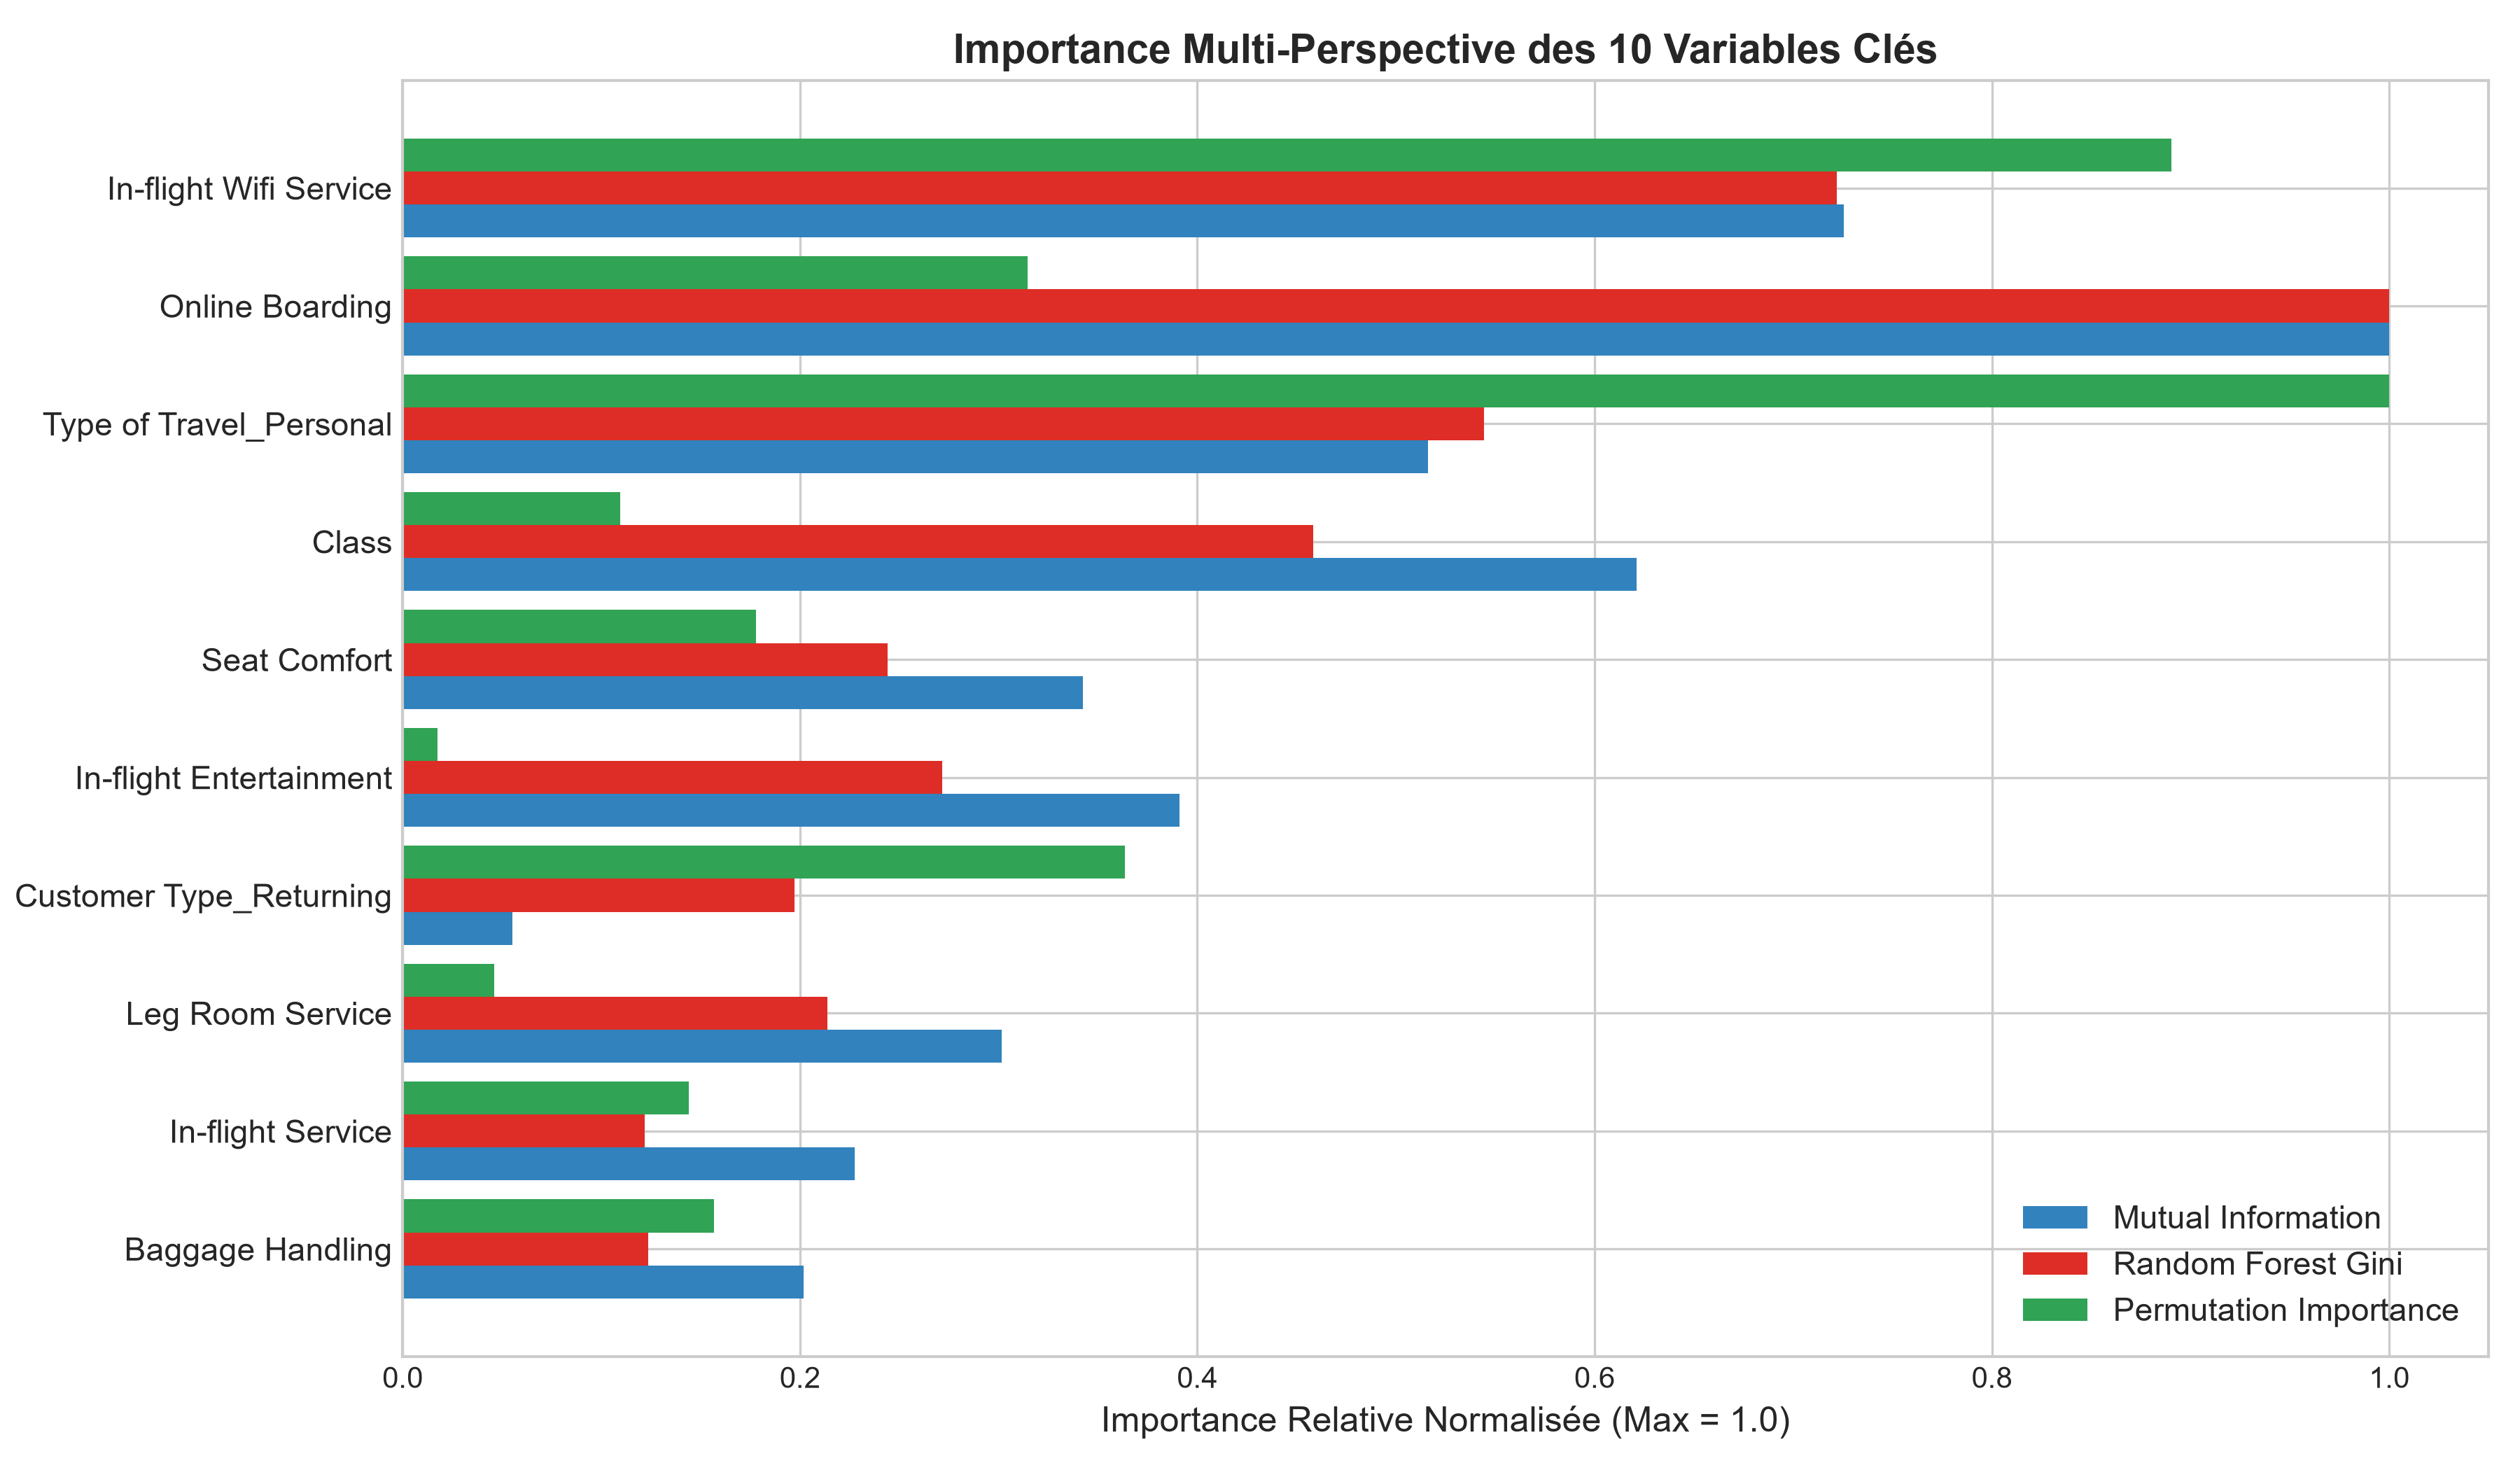

In [6]:
feat_img = "../data/figures/feature_importance_comparison.png"
if not os.path.exists(feat_img):
    feat_img = "data/figures/feature_importance_comparison.png"
if os.path.exists(feat_img):
    display(Image(filename=feat_img))


## 5. Synthèse et Choix du Meilleur Modèle
- Le modèle **Random Forest** et le modèle **Support Vector Machine (RBF)** se distinguent nettement avec des scores d'Accuracy et de ROC-AUC exceptionnels (> 0.95).
- Random Forest offre en outre un temps d'inférence ultra-rapide et une robustesse exemplaire face aux valeurs extrêmes et aux interactions non linéaires.
- Le pipeline complet est exporté au format `joblib` et directement déployé au sein de l'application Streamlit (`src/app.py`).
